# GRASP con *savings* (Clarke-Wright) para el TSP: RCL estándar vs. *biased randomization*

**Objetivo.** Entender la estructura de un GRASP estándar con una implementación lo más sencilla posible y comprobar si sustituir la RCL uniforme por una **selección sesgada** mejora los resultados. La constructiva es el algoritmo de **ahorros de Clarke-Wright**, que es donde se propuso originalmente la *biased randomization*.

## ¿Qué es un GRASP?

*Greedy Randomized Adaptive Search Procedure*: un método **multi-arranque** en el que cada iteración tiene dos fases independientes.

```
mejor = ninguno
repetir ITERS veces:
    1. CONSTRUCCIÓN  : crear una solución paso a paso, eligiendo en cada paso
                       uno de los "mejores" candidatos, con algo de azar
    2. BÚSQUEDA LOCAL: mejorarla hasta un óptimo local (aquí, 2-opt)
    3. si es mejor que la mejor conocida, guardarla
devolver mejor
```

- **Greedy**: los candidatos se valoran con un criterio voraz (aquí, el ahorro).
- **Randomized**: no se elige siempre el mejor; el azar da **diversidad** para que cada iteración explore una zona distinta.
- **Adaptive**: tras cada elección se actualiza qué candidatos siguen siendo válidos.

Lo único que cambia entre las variantes comparadas es **cómo se elige el candidato** en el paso 1. Todo lo demás es idéntico.

In [1]:
import os, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from numba import njit

TSP_DIR = "ALL_tsp"                       # carpeta con los .tsp y .opt.tour
TEST_INSTANCES   = ["eil51", "berlin52", "st70", "eil76", "kroA100", "ch130", "a280"]
TUNING_INSTANCES = ["kroB100", "eil101", "ch150"]   # distintas de las de test
ITERS, RUNS           = 150, 20           # iteraciones GRASP por ejecución, ejecuciones por variante
TUNE_ITERS, TUNE_RUNS = 80, 6
SEED_TEST, SEED_TUNE  = 0, 10_000

COL = {"GRASP estándar (RCL)": "#2a78d6", "Sesgada geométrica": "#eb6834",
       "Sesgada triangular": "#1baf7a", "Sesgada Zipf": "#eda100", "Sesgada softmax": "#4a3aa7"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold"})

## 1. Lectura de instancias TSPLIB

Todas las instancias usadas son `EUC_2D`: distancia euclídea **redondeada al entero más próximo**, como exige TSPLIB para que los óptimos publicados sean comparables. El óptimo se obtiene evaluando el fichero `.opt.tour`.

In [2]:
def read_coords(path):
    coords, reading, ewt = [], False, None
    for line in open(path):
        line = line.strip()
        if line.startswith("EDGE_WEIGHT_TYPE"): ewt = line.split(":")[1].strip()
        elif line.startswith("NODE_COORD_SECTION"): reading = True
        elif line == "EOF": break
        elif reading: _, x, y = line.split()[:3]; coords.append((float(x), float(y)))
    assert ewt == "EUC_2D", f"{path}: solo se implementa EUC_2D"
    return np.array(coords)

def read_tour(path):
    lines = open(path).read().split("TOUR_SECTION")[1].split()
    tour = []
    for tok in lines:
        if tok in ("-1", "EOF"): break
        tour.append(int(tok) - 1)
    return np.array(tour)

def tour_length(D, tour):
    return D[tour, np.roll(tour, -1)].sum()

def load_instance(name):
    xy = read_coords(f"{TSP_DIR}/{name}.tsp")
    D = np.floor(np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1)) + 0.5)
    opt = tour_length(D, read_tour(f"{TSP_DIR}/{name}.opt.tour")) if os.path.exists(f"{TSP_DIR}/{name}.opt.tour") \
          else {"kroB100": 22141}[name]
    return {"name": name, "xy": xy, "D": D, "n": len(xy), "opt": float(opt)}

INST = {n: load_instance(n) for n in TEST_INSTANCES + TUNING_INSTANCES}
pd.DataFrame([(k, v["n"], v["opt"]) for k, v in INST.items()], columns=["instancia", "n", "óptimo"]).set_index("instancia").T

instancia,eil51,berlin52,st70,eil76,kroA100,ch130,a280,kroB100,eil101,ch150
n,51.0,52.0,70.0,76.0,100.0,130.0,280.0,100.0,101.0,150.0
óptimo,426.0,7542.0,675.0,538.0,21282.0,6110.0,2579.0,22141.0,629.0,6528.0


## 2. Ahorros de Clarke-Wright

Se escoge un nodo **hub** (aquí, el más cercano al centro de gravedad). La solución de partida es absurda: ir y volver desde el hub a cada cliente (hub→i→hub). Unir dos clientes *i* y *j* directamente evita pasar dos veces por el hub y **ahorra**

$$s(i,j) = d(h,i) + d(h,j) - d(i,j).$$

La lista de ahorros se calcula **una sola vez** por instancia y se ordena de mayor a menor. Es la lista de candidatos del GRASP.

In [3]:
def prepare_savings(inst):
    D, xy = inst["D"], inst["xy"]
    hub = int(np.argmin(((xy - xy.mean(0)) ** 2).sum(1)))          # nodo más central
    others = np.array([v for v in range(inst["n"]) if v != hub])
    a, b = np.triu_indices(len(others), 1)                          # todos los pares i < j
    i, j = others[a], others[b]
    s = D[hub, i] + D[hub, j] - D[i, j]
    order = np.argsort(-s, kind="stable")                           # de mayor a menor ahorro
    inst.update(hub=hub, SI=i[order], SJ=j[order], SS=s[order])

for inst in INST.values(): prepare_savings(inst)
I = INST["kroA100"]
print(f"kroA100: hub = {I['hub']}, {len(I['SS'])} pares candidatos, mayores ahorros: {I['SS'][:5]}")

kroA100: hub = 57, 4851 pares candidatos, mayores ahorros: [3989. 3963. 3956. 3892. 3888.]


## 3. Regla de selección: lo único que cambia entre variantes

Cada función recibe la lista de ahorros **factibles**, ordenada de mayor a menor, y devuelve la **posición** del candidato elegido.

| Variante | Cómo elige | Parámetro | Mira… |
|---|---|---|---|
| **GRASP estándar (RCL)** | Uniforme entre los candidatos con ahorro ≥ s_max − α·(s_max − s_min) | α ∈ [0,1] | valor (corte duro) |
| **Geométrica** | P(pos = k) ∝ β(1−β)^k | β ∈ (0,1) | posición |
| **Triangular** | Densidad lineal decreciente sobre las primeras L = ⌈f·m⌉ posiciones | f ∈ (0,1] | posición |
| **Zipf** | P(pos = k) ∝ 1/(k+1)^e | e > 0 | posición |
| **Softmax** | P(k) ∝ exp(z_k / T), con z_k = (s_k − s_max)/(s_max − s_min) ∈ [−1, 0] | T > 0 | **valor** |

La RCL tiene un corte: dentro todos valen igual, fuera ninguno. Las sesgadas no cortan: todos los candidatos tienen probabilidad, decreciente. **Softmax** es distinta a las otras tres: no usa la posición sino el **valor** del ahorro normalizado, así que dos candidatos con ahorros casi iguales tienen casi la misma probabilidad aunque estén en posiciones distintas.

In [4]:
def pick_from_weights(w, rng):                   # elegir un índice con probabilidad ∝ w
    c = np.cumsum(w); return int(np.searchsorted(c, rng.random() * c[-1], side="right"))

def select_rcl(s, alpha, rng):
    threshold = s[0] - alpha * (s[0] - s[-1])
    size = np.count_nonzero(s >= threshold)      # s está ordenado: la RCL son las 'size' primeras
    return rng.integers(size)

def select_geometric(s, beta, rng):
    m, u = len(s), rng.random()
    if beta >= 1: return 0
    k = int(math.log(1 - u * (1 - (1 - beta) ** m)) / math.log(1 - beta))  # inversa de la CDF truncada
    return min(k, m - 1)

def select_triangular(s, f, rng):
    L = min(len(s), max(3, math.ceil(f * len(s))))
    return min(int(L * (1 - math.sqrt(1 - rng.random()))), L - 1)

def select_zipf(s, e, rng):
    return pick_from_weights(np.arange(1.0, len(s) + 1) ** (-e), rng)

def select_softmax(s, T, rng):
    z = (s - s[0]) / (s[0] - s[-1] + 1e-12)
    return pick_from_weights(np.exp(z / T), rng)

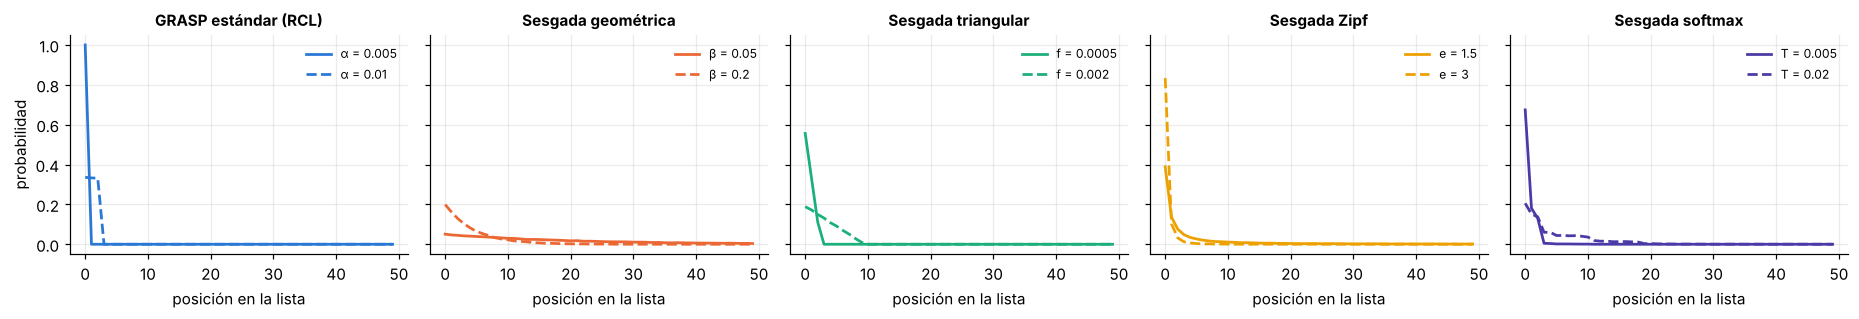

In [5]:
# Probabilidad de cada posición con la lista de ahorros real de kroA100 (primer paso, 50 primeras posiciones)
s = INST["kroA100"]["SS"]; m = 50
def pmf_by_sampling(fn, p, reps=40_000):
    rng = np.random.default_rng(1); c = np.bincount([fn(s, p, rng) for _ in range(reps)], minlength=len(s))
    return c[:m] / reps
fig, ax = plt.subplots(1, 5, figsize=(17, 3), sharey=True)
for a, (name, fn, ps, lab) in zip(ax, [
        ("GRASP estándar (RCL)", select_rcl, [.005, .01], "α"), ("Sesgada geométrica", select_geometric, [.05, .2], "β"),
        ("Sesgada triangular", select_triangular, [.0005, .002], "f"), ("Sesgada Zipf", select_zipf, [1.5, 3], "e"),
        ("Sesgada softmax", select_softmax, [.005, .02], "T")]):
    for p, ls in zip(ps, ["-", "--"]):
        a.plot(range(m), pmf_by_sampling(fn, p), ls, color=COL[name], lw=1.8, label=f"{lab} = {p}")
    a.set_title(name, fontsize=10); a.set_xlabel("posición en la lista"); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel("probabilidad")
plt.tight_layout(); plt.show()

## 4. Fase 1: construcción aleatorizada con ahorros

Cada cliente empieza siendo su propia ruta. En cada paso:

1. **Filtrar** los candidatos factibles: unir *i* y *j* solo es posible si ambos son **extremos** de su ruta (grado < 2) y están en **rutas distintas** (si no, se cerraría un ciclo). Como un par que deja de ser factible no vuelve a serlo, se elimina de la lista para siempre.
2. **Elegir** un par con la regla de selección.
3. **Unir** las dos rutas.

Tras n − 2 uniones queda un único camino; se cierra uniendo sus dos extremos al hub.

In [6]:
def construct_savings(inst, select, p, rng):
    n, hub = inst["n"], inst["hub"]
    SI, SJ, SS = inst["SI"], inst["SJ"], inst["SS"]
    degree = np.zeros(n, dtype=int)               # nº de vecinos (sin contar el hub)
    route = np.arange(n)                          # identificador de ruta de cada nodo
    neighbours = [[] for _ in range(n)]
    for _ in range(n - 2):
        feasible = (degree[SI] < 2) & (degree[SJ] < 2) & (route[SI] != route[SJ])
        SI, SJ, SS = SI[feasible], SJ[feasible], SS[feasible]      # 1. filtrar
        k = select(SS, p, rng)                                       # 2. elegir
        i, j = SI[k], SJ[k]                                          # 3. unir
        neighbours[i].append(j); neighbours[j].append(i)
        degree[i] += 1; degree[j] += 1
        route[route == route[j]] = route[i]
    # recorrer el camino desde un extremo hasta el otro, empezando y terminando en el hub
    start = next(v for v in range(n) if v != hub and degree[v] == 1)
    tour = [hub, start]
    while len(tour) < n:
        tour.append(next(w for w in neighbours[tour[-1]] if w != tour[-2]))
    return np.array(tour, dtype=np.int64)

## 5. Fase 2: búsqueda local 2-opt

Para cada par de aristas (a,b) y (c,d) del tour, si sustituirlas por (a,c) y (b,d) acorta el tour, se invierte el tramo b…c. Se aplica la **primera mejora** encontrada y se repite hasta que ninguna mejora (óptimo local).

Se compila con `numba` solo por velocidad: la lógica es exactamente la descrita.

In [7]:
@njit(cache=True)
def two_opt(D, t):
    n = len(t); improved = True
    while improved:
        improved = False
        for i in range(n - 2):
            for j in range(i + 2, n if i > 0 else n - 1):
                a, b, c, d = t[i], t[i + 1], t[j], t[(j + 1) % n]
                if D[a, c] + D[b, d] < D[a, b] + D[c, d] - 1e-9:
                    t[i + 1:j + 1] = t[i + 1:j + 1][::-1].copy()     # invertir el tramo b…c
                    improved = True
    return t

## 6. El GRASP completo

Exactamente el pseudocódigo del principio. La función `select` (y su parámetro `p`) es lo único que distingue un GRASP estándar de uno con *biased randomization*.

In [8]:
def grasp(inst, select, p, iters, seed):
    rng = np.random.default_rng(seed)
    best_tour, best_cost, history = None, np.inf, []
    for _ in range(iters):
        tour = construct_savings(inst, select, p, rng)    # 1. construcción voraz aleatorizada
        tour = two_opt(inst["D"], tour)                    # 2. búsqueda local
        cost = tour_length(inst["D"], tour)
        if cost < best_cost:                               # 3. actualizar la mejor solución
            best_tour, best_cost = tour.copy(), cost
        history.append(best_cost)
    return best_tour, best_cost, np.array(history)

def gap(cost, opt): return 100 * (cost / opt - 1)

# Comprobaciones y referencia: Clarke-Wright determinista (α = 0) con y sin 2-opt
rows = []
for name in TEST_INSTANCES:
    inst = INST[name]
    t = construct_savings(inst, select_rcl, 0.0, np.random.default_rng(0))
    assert sorted(t) == list(range(inst["n"])), "el tour no es una permutación"
    c_cw = tour_length(inst["D"], t); c_2opt = tour_length(inst["D"], two_opt(inst["D"], t))
    rows.append((name, gap(c_cw, inst["opt"]), gap(c_2opt, inst["opt"])))
REF = pd.DataFrame(rows, columns=["instancia", "CW determinista", "CW determinista + 2-opt"]).set_index("instancia")
print("Gap (%) de las heurísticas deterministas de referencia")
REF.round(2)

Gap (%) de las heurísticas deterministas de referencia


,CW determinista,CW determinista + 2-opt
instancia,,
eil51,5.40,4.46
berlin52,11.06,6.58
st70,4.74,3.56
eil76,5.02,3.53
kroA100,6.04,3.18
ch130,7.28,4.70
a280,13.65,9.46


## 7. Ajuste de parámetros

Cada variante recibe el **mismo esfuerzo de ajuste**: una rejilla de 6-8 valores que va desde casi voraz hasta muy aleatorio, evaluada en instancias **distintas** de las de test (`kroB100`, `eil101`, `ch150`) y con semillas distintas. Se elige el valor con menor gap medio. Si el mejor cae en el borde de su rejilla, se avisa: significaría que la rejilla se ha quedado corta.

Ajuste: 306 s. Parámetros elegidos: {'GRASP estándar (RCL)': 0.05, 'Sesgada Zipf': 3.0, 'Sesgada geométrica': 0.4, 'Sesgada softmax': 0.02, 'Sesgada triangular': 0.002}


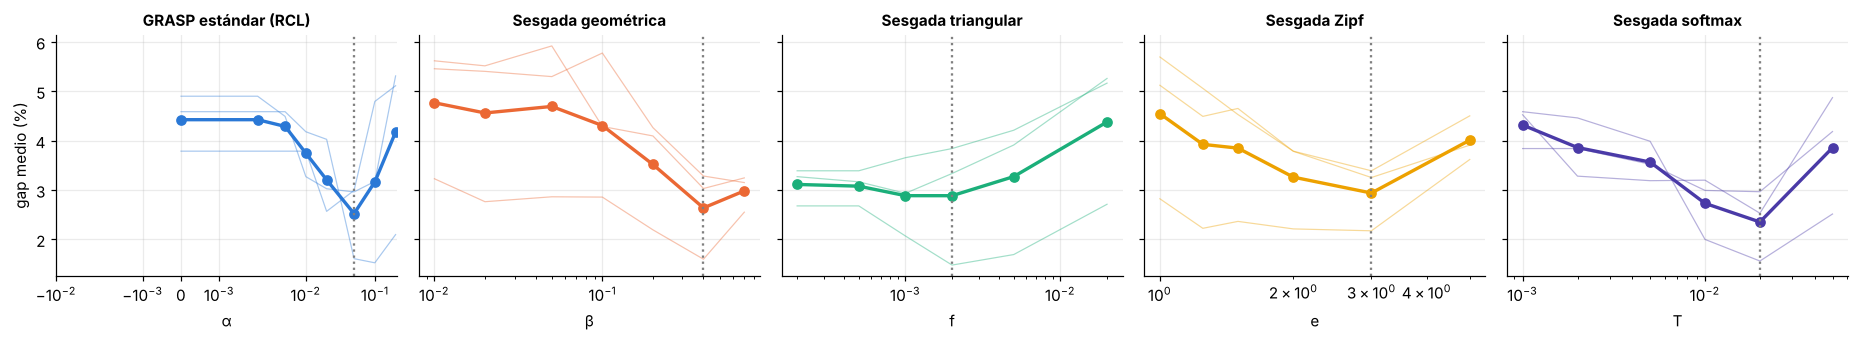

In [9]:
VARIANTS = {   # nombre: (función de selección, nombre del parámetro, rejilla)
    "GRASP estándar (RCL)": (select_rcl,        "α", [0.0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2]),
    "Sesgada geométrica":   (select_geometric,  "β", [0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7]),
    "Sesgada triangular":   (select_triangular, "f", [0.0002, 0.0005, 0.001, 0.002, 0.005, 0.02]),
    "Sesgada Zipf":         (select_zipf,       "e", [1.0, 1.25, 1.5, 2.0, 3.0, 5.0]),
    "Sesgada softmax":      (select_softmax,    "T", [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]),
}
two_opt(INST["eil51"]["D"], np.arange(51))            # compilar numba

t0 = time.time(); rows = []
for vname, (fn, pname, grid) in VARIANTS.items():
    for p in grid:
        for iname in TUNING_INSTANCES:
            for r in range(TUNE_RUNS):
                _, c, _ = grasp(INST[iname], fn, p, TUNE_ITERS, SEED_TUNE + r)
                rows.append((vname, p, iname, gap(c, INST[iname]["opt"])))
tune = pd.DataFrame(rows, columns=["variante", "param", "instancia", "gap"])
tune_mean = tune.groupby(["variante", "param"]).gap.mean().reset_index()
BEST = {v: float(g.loc[g.gap.idxmin(), "param"]) for v, g in tune_mean.groupby("variante")}
print(f"Ajuste: {time.time() - t0:.0f} s. Parámetros elegidos: {BEST}")
for v, (_, pname, grid) in VARIANTS.items():
    if BEST[v] in (grid[0], grid[-1]): print(f"AVISO: «{v}» tiene el óptimo en el borde de la rejilla ({pname} = {BEST[v]})")

fig, ax = plt.subplots(1, 5, figsize=(17, 3.2), sharey=True)
for a, (v, (_, pname, grid)) in zip(ax, VARIANTS.items()):
    for iname in TUNING_INSTANCES:
        g = tune[(tune.variante == v) & (tune.instancia == iname)].groupby("param").gap.mean()
        a.plot(g.index, g.values, color=COL[v], lw=.8, alpha=.4)
    g = tune_mean[tune_mean.variante == v]
    a.plot(g.param, g.gap, "o-", color=COL[v], lw=2.2); a.axvline(BEST[v], ls=":", color="gray")
    a.set_xscale("symlog", linthresh=grid[1]) if grid[0] == 0 else a.set_xscale("log")
    a.set_title(v, fontsize=10); a.set_xlabel(pname)
ax[0].set_ylabel("gap medio (%)")
plt.tight_layout(); plt.show()

## 8. Experimento: todas las variantes en las instancias de test

Mismo número de iteraciones, mismas semillas (0…RUNS−1), mismo hub, misma búsqueda local. Se guarda el coste final, el tiempo y la curva de convergencia de cada ejecución.

In [10]:
t0 = time.time(); rec, curves, best_tours = [], {}, {}
for iname in TEST_INSTANCES:
    inst = INST[iname]
    for v, (fn, _, _) in VARIANTS.items():
        H = []
        for r in range(RUNS):
            ts = time.perf_counter()
            tour, c, h = grasp(inst, fn, BEST[v], ITERS, SEED_TEST + r)
            rec.append((iname, v, r, c, gap(c, inst["opt"]), time.perf_counter() - ts)); H.append(h)
            if (iname, v) not in best_tours or c < best_tours[(iname, v)][0]: best_tours[(iname, v)] = (c, tour)
        curves[(iname, v)] = np.array(H)
res = pd.DataFrame(rec, columns=["instancia", "variante", "run", "coste", "gap", "tiempo"])
print(f"Experimento: {time.time() - t0:.0f} s, {len(res)} ejecuciones")

Experimento: 1011 s, 700 ejecuciones


In [11]:
order, V = TEST_INSTANCES, list(VARIANTS)
tab = res.groupby(["instancia", "variante"]).gap.mean().unstack().loc[order, V]
tab.insert(0, "CW det. + 2-opt", REF.loc[order, "CW determinista + 2-opt"])
tab.loc["MEDIA"] = tab.mean()
print(f"Gap medio (%) sobre el óptimo — {RUNS} ejecuciones × {ITERS} iteraciones")
display(tab.round(2).style.background_gradient(cmap="Blues_r", axis=1).format("{:.2f}"))

best = res.groupby(["instancia", "variante"]).gap.min().unstack().loc[order, V]
print("Mejor gap (%) encontrado")
display(best.round(2))
print("Tiempo medio por ejecución (s)")
res.groupby(["instancia", "variante"]).tiempo.mean().unstack().loc[order, V].round(2)

Gap medio (%) sobre el óptimo — 20 ejecuciones × 150 iteraciones


variante,CW det. + 2-opt,GRASP estándar (RCL),Sesgada geométrica,Sesgada triangular,Sesgada Zipf,Sesgada softmax
instancia,,,,,,
eil51,4.46,1.41,1.10,0.95,1.20,1.41
berlin52,6.58,3.69,0.93,2.04,3.35,3.44
st70,3.56,0.82,1.01,0.99,1.26,0.93
eil76,3.53,1.78,1.65,1.66,2.02,1.89
kroA100,3.18,0.94,1.14,1.12,1.19,0.91
ch130,4.70,1.71,1.73,1.80,1.54,1.46
a280,9.46,5.16,4.31,6.14,4.74,5.70
MEDIA,5.07,2.22,1.70,2.10,2.18,2.25


Mejor gap (%) encontrado


variante,GRASP estándar (RCL),Sesgada geométrica,Sesgada triangular,Sesgada Zipf,Sesgada softmax
instancia,,,,,
eil51,1.41,0.47,0.47,0.47,1.41
berlin52,3.62,0.00,0.00,0.00,1.01
st70,0.15,0.15,0.15,0.89,0.15
eil76,1.30,0.19,0.56,0.93,1.49
kroA100,0.47,0.47,0.47,0.47,0.47
ch130,0.93,1.11,1.11,1.00,1.00
a280,3.99,3.30,3.99,4.15,4.73


Tiempo medio por ejecución (s)


variante,GRASP estándar (RCL),Sesgada geométrica,Sesgada triangular,Sesgada Zipf,Sesgada softmax
instancia,,,,,
eil51,0.17,0.15,0.14,0.25,0.22
berlin52,0.16,0.15,0.14,0.23,0.25
st70,0.31,0.24,0.27,0.39,0.43
eil76,0.34,0.28,0.28,0.44,0.44
kroA100,0.51,0.48,0.46,0.76,0.79
ch130,0.95,0.81,0.81,1.49,1.41
a280,5.81,5.33,5.53,10.18,9.93


### ¿Son significativas las diferencias?

Para cada instancia y cada variante sesgada se compara su distribución de costes con la del GRASP estándar mediante el test de **Wilcoxon de suma de rangos** (Mann-Whitney U) **bilateral**, con corrección de **Holm** por comparaciones múltiples. *P(superior)* es la probabilidad de que una ejecución de la variante sea mejor que una del estándar (0.5 = empate). El test de **Friedman** compara todas las variantes a la vez usando las instancias como bloques.

In [12]:
BASE = "GRASP estándar (RCL)"
rows = []
for iname in order:
    base = res[(res.instancia == iname) & (res.variante == BASE)].coste.values
    for v in V[1:]:
        x = res[(res.instancia == iname) & (res.variante == v)].coste.values
        p = stats.mannwhitneyu(x, base, alternative="two-sided").pvalue
        sup = stats.mannwhitneyu(base, x, alternative="greater").statistic / (len(x) * len(base))
        rows.append((iname, v, x.mean() - base.mean(), sup, p))
sig = pd.DataFrame(rows, columns=["instancia", "variante", "Δ coste medio", "P(superior)", "p"])
m = len(sig); o = np.argsort(sig.p.values); adj = np.empty(m); run = 0
for k, idx in enumerate(o): run = max(run, (m - k) * sig.p.values[idx]); adj[idx] = min(1, run)
sig["p_Holm"] = adj
sig["veredicto"] = np.where(sig.p_Holm >= .05, "=", np.where(sig["Δ coste medio"] < 0, "MEJOR", "peor"))

print("Veredicto frente al GRASP estándar (Holm, 5 %):  MEJOR / = / peor")
display(sig.pivot(index="instancia", columns="variante", values="veredicto").loc[order, V[1:]])
summary = sig.groupby("variante").agg(P_superior_media=("P(superior)", "mean")).round(3)
for k in ["MEJOR", "=", "peor"]: summary[k] = sig.groupby("variante").veredicto.apply(lambda s: (s == k).sum())
fr = stats.friedmanchisquare(*[tab.loc[order, v].values for v in V])
print(f"Friedman ({len(order)} instancias, {len(V)} variantes): χ² = {fr.statistic:.2f}, p = {fr.pvalue:.4f}")
summary.loc[V[1:]]

Veredicto frente al GRASP estándar (Holm, 5 %):  MEJOR / = / peor


variante,Sesgada geométrica,Sesgada triangular,Sesgada Zipf,Sesgada softmax
instancia,,,,
eil51,=,MEJOR,=,=
berlin52,MEJOR,MEJOR,=,=
st70,=,=,peor,=
eil76,=,=,=,=
kroA100,=,=,=,=
ch130,=,=,=,=
a280,MEJOR,peor,=,=


Friedman (7 instancias, 5 variantes): χ² = 1.87, p = 0.7596


,P_superior_media,MEJOR,=,peor
variante,,,,
Sesgada geométrica,0.602,2,5,0
Sesgada triangular,0.512,2,4,1
Sesgada Zipf,0.449,0,6,1
Sesgada softmax,0.488,0,7,0


## 9. Gráficas

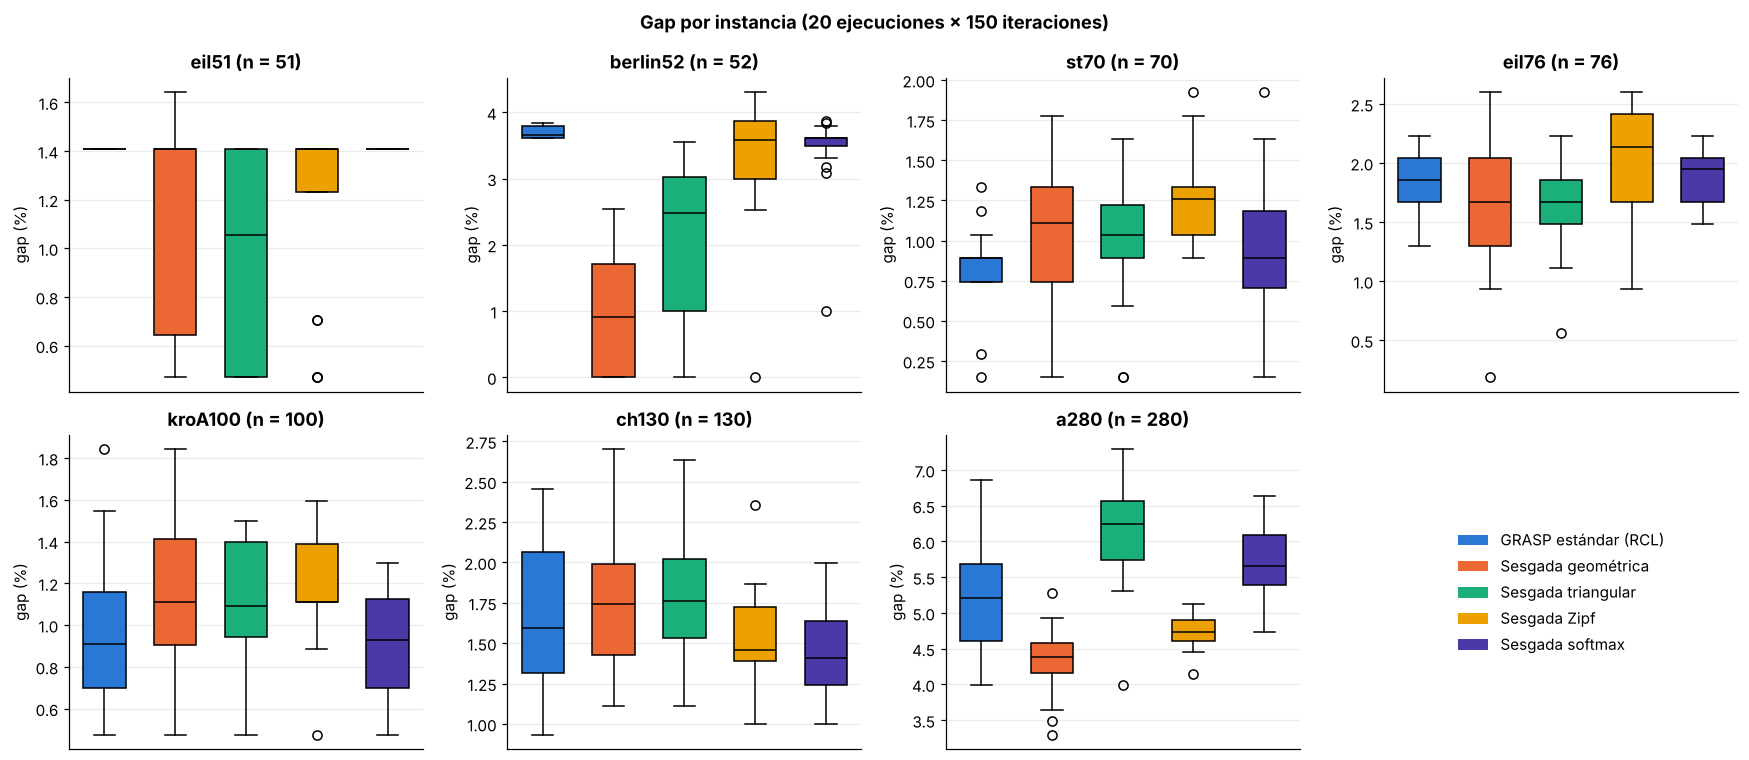

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for a, iname in zip(axes.ravel(), order):
    bp = a.boxplot([res[(res.instancia == iname) & (res.variante == v)].gap for v in V],
                   patch_artist=True, widths=.6, medianprops=dict(color="black"))
    for box, v in zip(bp["boxes"], V): box.set_facecolor(COL[v])
    a.set_title(f"{iname} (n = {INST[iname]['n']})"); a.set_xticks([]); a.set_ylabel("gap (%)")
axes[1, 3].axis("off")
axes[1, 3].legend([plt.Rectangle((0, 0), 1, 1, fc=COL[v]) for v in V], V, loc="center", frameon=False)
plt.suptitle(f"Gap por instancia ({RUNS} ejecuciones × {ITERS} iteraciones)", fontweight="bold")
plt.tight_layout(); plt.show()

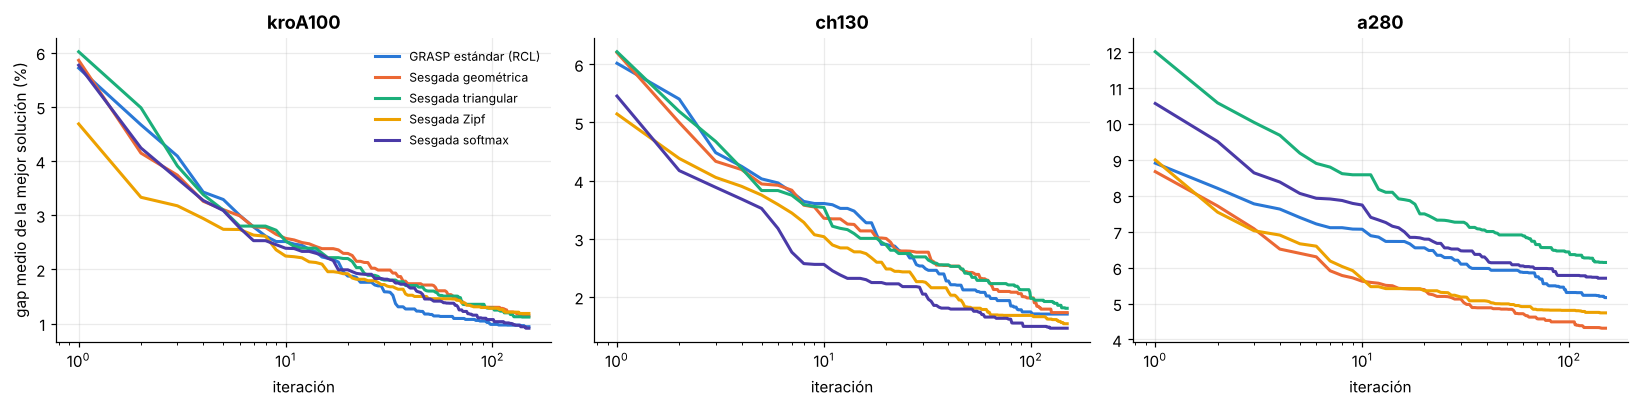

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for a, iname in zip(axes, ["kroA100", "ch130", "a280"]):
    for v in V:
        a.plot(range(1, ITERS + 1), gap(curves[(iname, v)].mean(0), INST[iname]["opt"]), color=COL[v], lw=2, label=v)
    a.set_xscale("log"); a.set_xlabel("iteración"); a.set_title(iname)
axes[0].set_ylabel("gap medio de la mejor solución (%)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

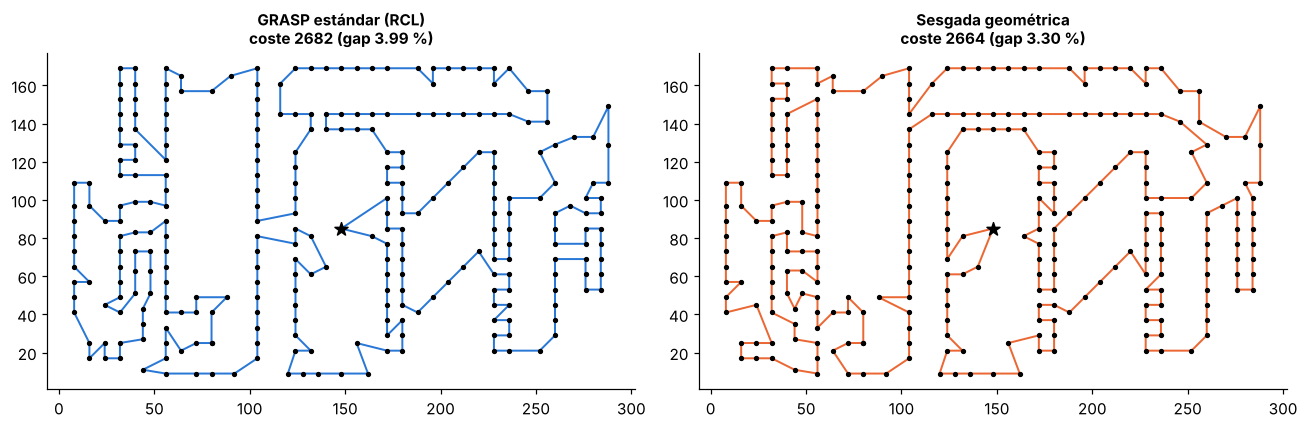

In [15]:
iname = "a280"; inst = INST[iname]; xy = inst["xy"]
best_biased = min(V[1:], key=lambda v: best_tours[(iname, v)][0])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for a, v in zip(axes, [BASE, best_biased]):
    c, t = best_tours[(iname, v)]; t = np.r_[t, t[0]]
    a.plot(xy[t, 0], xy[t, 1], "-", color=COL[v], lw=1.3)
    a.scatter(xy[:, 0], xy[:, 1], s=6, color="k", zorder=3)
    a.scatter(*xy[inst["hub"]], s=80, marker="*", color="k", zorder=4)
    a.set_title(f"{v}\ncoste {c:.0f} (gap {gap(c, inst['opt']):.2f} %)", fontsize=10); a.set_aspect("equal"); a.grid(False)
plt.tight_layout(); plt.show()

## 10. Conclusiones

**1. El GRASP funciona.** Frente a Clarke-Wright determinista + 2-opt (gap medio 5.07 %), cualquier GRASP baja a ≈ 1.7-2.3 %. La diversidad que introduce la aleatorización, combinada con la búsqueda local, es lo que aporta la mejora.

**2. La *biased randomization* geométrica es la única con una ventaja consistente.**
- Gap medio 1.70 % frente a 2.22 % del GRASP estándar (≈ 23 % menos de error relativo).
- Significativamente mejor en berlin52 y a280, y **nunca significativamente peor**.
- P(superior) media de 0.60 y el mismo tiempo de cálculo que la RCL.

**3. El resto de distribuciones no mejora a la RCL de forma consistente.**
- *Triangular:* resultado mixto, mejor en eil51 y berlin52 pero peor en a280.
- *Zipf* y *softmax:* equivalentes a la RCL. Además son unas dos veces más lentas, porque calculan un peso para toda la lista en cada paso.
- *Softmax* mira el valor del ahorro, y los mayores ahorros tienen valores muy parecidos entre sí. En la práctica reparte la probabilidad casi uniformemente entre el bloque de cabeza, y por eso se comporta como una RCL.

**4. Por qué la geométrica ayuda aquí.** La RCL por valor depende de la escala de los ahorros. Con distancias enteras pequeñas, como en eil51, entran muy pocos candidatos en la RCL y las 20 ejecuciones acaban en la misma solución (caja plana en el boxplot). La geométrica da una diversidad controlada que no depende de esa escala.

**5. Cautela estadística.** El test de Friedman con las 7 instancias no detecta diferencias globales (p ≈ 0.76). La evidencia a favor de la geométrica es moderada (2 de 7 instancias significativas, ninguna en contra), no concluyente.

**Comparación con la versión de vecino más próximo.** Allí ninguna distribución mostraba ventaja consistente. Con *savings*, la geométrica sí la muestra, lo que encaja con que la técnica se propusiera precisamente sobre la lista de ahorros. Los presupuestos de ambos notebooks son distintos, así que esta comparación es solo cualitativa.

**Para reforzar el resultado:** más instancias de test (sobre todo ≥ 200 nodos, donde la ventaja es mayor), más ejecuciones y un experimento a igual tiempo de CPU.
